<a href="https://colab.research.google.com/github/Alina110401/Analizator-FASTA/blob/master/Projekt_1_159160_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Na pierwszym etapie sprawdzimy:
1. Ile modeli RNA znajduje się w zbiorze.
2. Czy wszystkie metryki są liczbowe.
3. Czy występują brakujące wartości.
4. Czy dane wymagają czyszczenia.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("R1107.csv")


display(df.head())


print("Liczba wierszy i kolumn:", df.shape)

df.info()


,#,Model,Group#,GroupName,RMSD,LDDT,TM_score,GDT_TS,Clash
0,1,R1107TS232_1,232,AIchemy_RNA2,4.52,0.724,0.564,63.41,14.93
1,2,R1107TS232_2,232,AIchemy_RNA2,4.85,0.721,0.498,58.69,9.05
2,3,R1107TS232_4,232,AIchemy_RNA2,5.31,0.710,0.488,56.88,11.76
3,4,R1107TS232_3,232,AIchemy_RNA2,5.94,0.728,0.487,54.34,17.19
4,5,R1107TS232_5,232,AIchemy_RNA2,5.02,0.721,0.473,59.06,10.40


Liczba wierszy i kolumn: (131, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131 entries, 0 to 130
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   #          131 non-null    int64  
 1   Model      131 non-null    object 
 2   Group#     131 non-null    object 
 3   GroupName  131 non-null    object 
 4   RMSD       131 non-null    float64
 5   LDDT       131 non-null    float64
 6   TM_score   131 non-null    float64
 7   GDT_TS     131 non-null    float64
 8   Clash      131 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 9.3+ KB


In [ ]:


df["GroupName"].nunique()


29

W pliku się znajduje 131 modeli przewidywanej struktury RNA i 29 różnych grup badawczych, które opracowały te modele.  Dane nie trzeba normalizowć.

# Tabela statystyk opisowych

Wartość minimalna	- min

Pierwszy kwartyl (25. percentyl)	- 25%

Mediana (50. percentyl)	- 50%

Trzeci kwartyl (75. percentyl)- 	75%

Wartość maksymalna	- max

Średnia arytmetyczna	- mean

Odchylenie standardowe	- std

Rozstęp	Rozstęp = max - min

Rozstęp międzykwartylowy	IQR = 75% - 25%

In [ ]:

metryki = ["RMSD", "LDDT", "TM_score",
           "GDT_TS", "Clash"]

dane = df[metryki]

statystyki = dane.describe().T

statystyki["Rozstęp"] = (
    statystyki["max"] - statystyki["min"]
)

statystyki["IQR"] = (
    statystyki["75%"] - statystyki["25%"]
)

statystyki = statystyki[
    ["min", "25%", "50%", "75%", "max",
     "mean", "std", "Rozstęp", "IQR"]
]

display(statystyki.round(3))


,min,25%,50%,75%,max,mean,std,Rozstęp,IQR
RMSD,4.520,11.635,18.980,23.540,67.980,19.881,12.565,63.460,11.905
LDDT,0.211,0.324,0.407,0.536,0.728,0.435,0.125,0.517,0.211
TM_score,0.135,0.232,0.264,0.336,0.564,0.285,0.086,0.429,0.105
GDT_TS,11.230,23.550,30.800,41.305,63.410,31.373,11.642,52.180,17.755
Clash,0.000,2.035,6.780,28.700,169.220,24.816,38.220,169.220,26.665


# Wnioski z analizy statystyk

Analiza 131 modeli RNA dla celu R1107 wykazała znaczne zróżnicowanie jakości przewidywanych struktur. Wartości RMSD wynosiły od 4,52 do 67,98 Å, co świadczy o dużych różnicach w dokładności dopasowania modeli do struktury referencyjnej.

Średnie wartości TM_score (0,285), LDDT (0,435) oraz GDT_TS (31,373) wskazują na ograniczoną dokładność przewidywanych struktur RNA.

Największą różnicę między średnią a medianą zaobserwowano dla metryki Clash (24,816 i 6,780), co sugeruje występowanie modeli o wyjątkowo dużej liczbie kolizji.

Podsumowując, modele różnią się zarówno dokładnością odwzorowania struktury RNA, jak i poprawnością geometryczną. Część modeli osiąga dobre wyniki w poszczególnych metrykach, jednak ogólna jakość przewidywań jest zróżnicowana.

# Etap 2. Wizualizacja rozkładów metryk CASP15

# Histogramy
Histogram dzieli wartości metryki na przedziały i pokazuje, ile modeli znalazło się w każdym przedziale.

Przykładowo dla RMSD zobaczymy, czy większość modeli osiąga niewielkie odchylenia od struktury referencyjnej, czy raczej duże.




# Wykresy pudełkowe (boxplot)

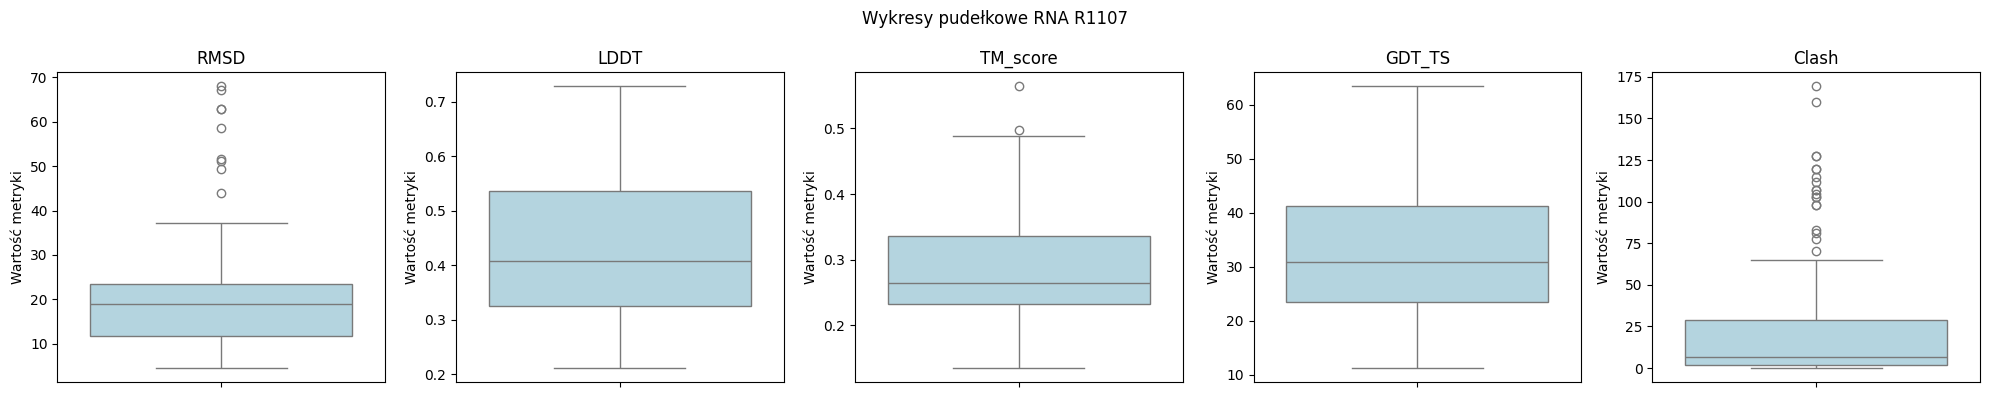

In [ ]:

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i, metryka in enumerate(metryki):
    sns.boxplot(
        y=df[metryka],
        color="lightblue",
        ax=axes[i]
    )

    axes[i].set_title(metryka)
    axes[i].set_ylabel("Wartość metryki")

plt.suptitle("Wykresy pudełkowe RNA R1107")
plt.tight_layout()
plt.show()


# Opis
### Interpretacja histogramów i wykresów pudełkowych

Histogramy pokazują zróżnicowanie wartości poszczególnych metryk oceny modeli RNA. Największą asymetrię prawostronną zaobserwowano dla RMSD i Clash, gdzie większość modeli osiąga stosunkowo niskie wartości, a nieliczne znacznie wyższe. Rozkłady LDDT, TM_score i GDT_TS są bardziej równomierne, choć nie są idealnie symetryczne.

Wykresy pudełkowe potwierdzają obecność wartości odstających, szczególnie dla RMSD i Clash. Największe zróżnicowanie wyników widoczne jest w metryce Clash, natomiast dla LDDT i GDT_TS nie zaobserwowano wartości odstających.

Wniosek: Modele RNA różnią się jakością strukturalną, szczególnie pod względem odchylenia od struktury referencyjnej (RMSD) oraz liczby kolizji sterycznych (Clash).

# Wykresy punktowe

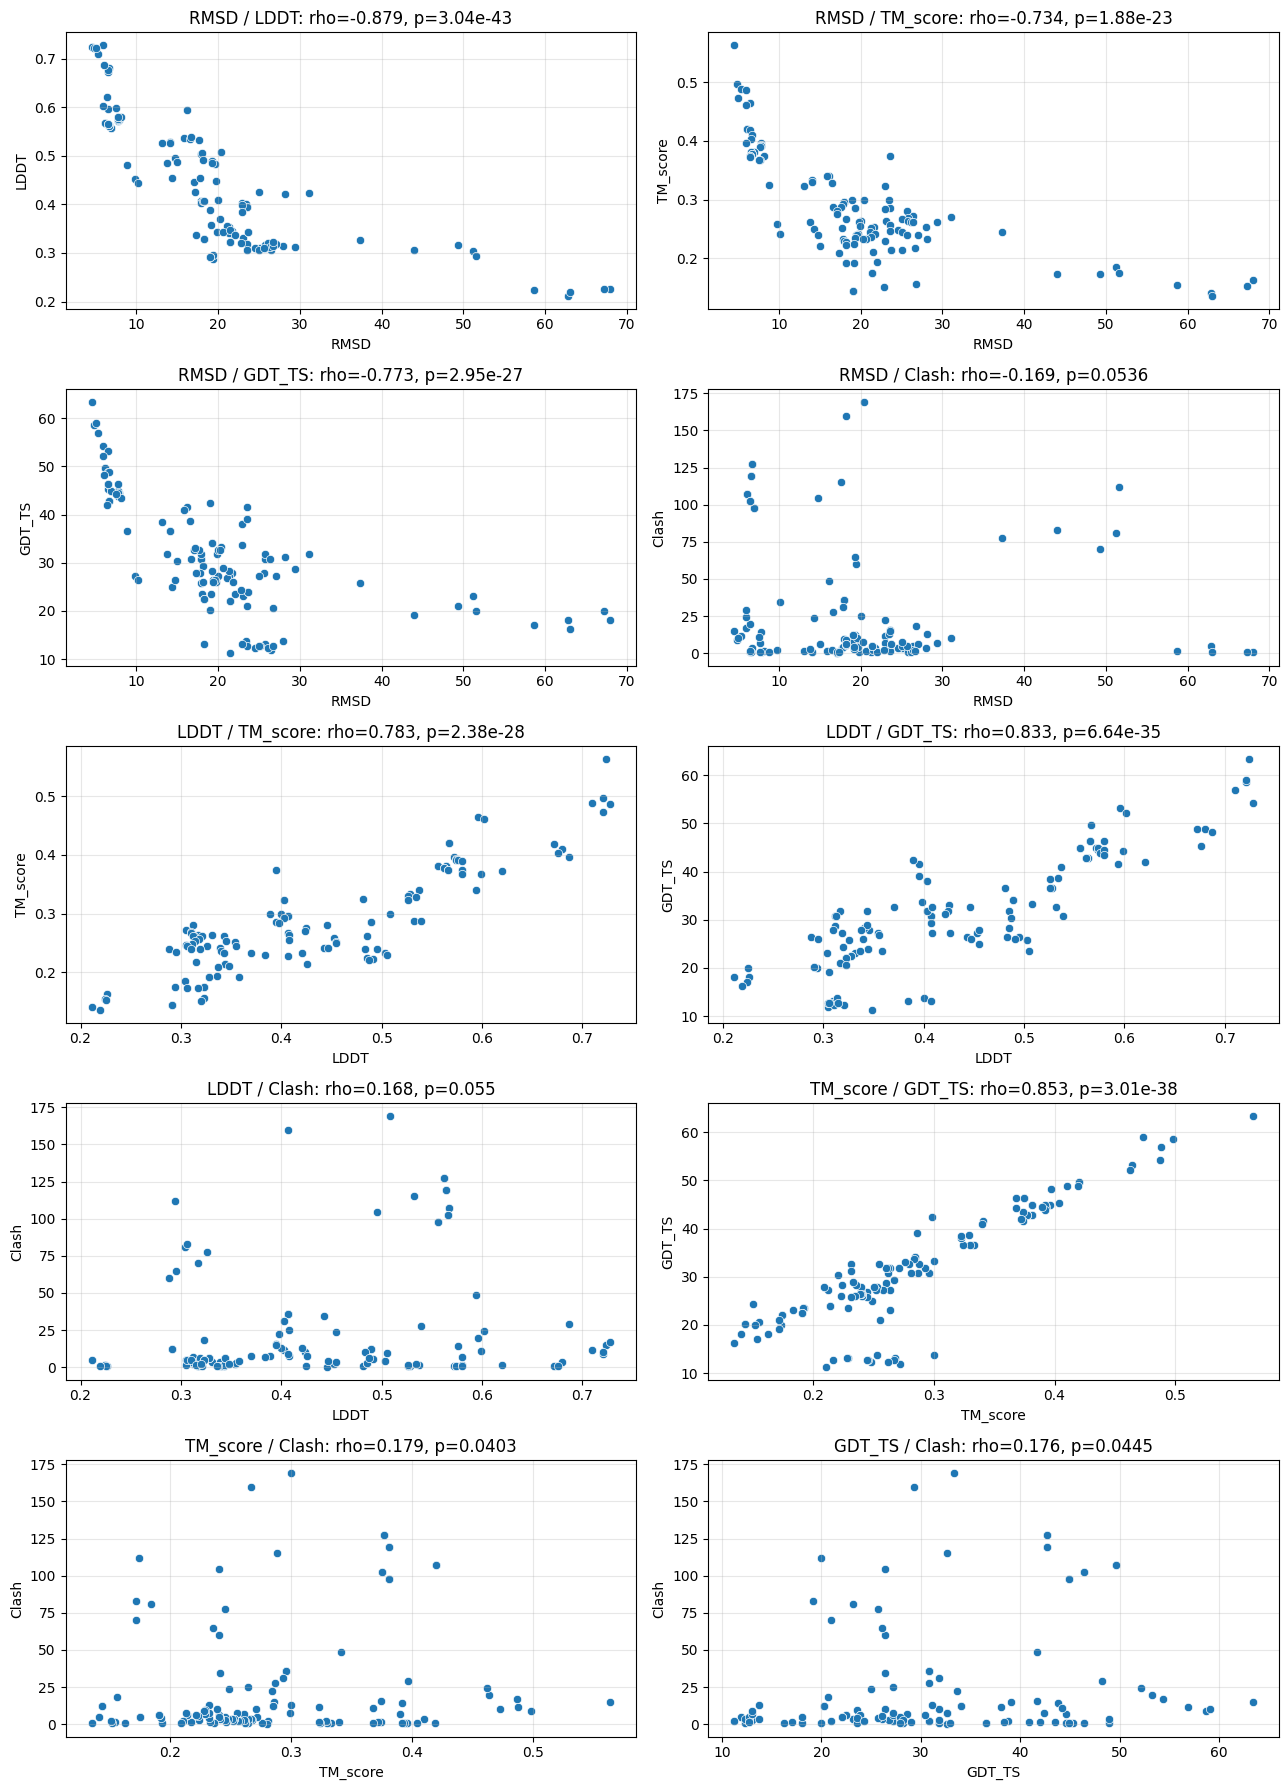

In [ ]:

from itertools import combinations
from scipy.stats import spearmanr

metryki = ["RMSD", "LDDT", "TM_score",
           "GDT_TS", "Clash"]

pary = list(combinations(metryki, 2))

fig, axes = plt.subplots(5, 2, figsize=(13, 18))

for ax, (x, y) in zip(axes.flat, pary):
    dane = df[[x, y]].dropna()
    rho, p = spearmanr(dane[x], dane[y])

    sns.scatterplot(
        data=dane,
        x=x,
        y=y,
        ax=ax
    )

    ax.set_title(
        f"{x} / {y}: rho={rho:.3f}, p={p:.3g}"
    )
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


#  Korelacja Spearmana: hipotezy i poziom istotności

In [ ]:

from scipy.stats import spearmanr
from itertools import combinations
import pandas as pd

metryki = ["RMSD", "LDDT", "TM_score", "GDT_TS", "Clash"]
pary = list(combinations(metryki, 2))

# Poziom istotności
alpha = 0.05
wyniki = []

for x, y in pary:
    rho, p = spearmanr(df[x], df[y], nan_policy="omit")

    wyniki.append({
        "Metryka 1": x,
        "Metryka 2": y,
        "Spearman rho": round(rho, 3),
        "p-value": p,
        "Istotność": "Tak" if p < alpha else "Nie"
    })

wyniki_df = pd.DataFrame(wyniki)

display(wyniki_df)


,Metryka 1,Metryka 2,Spearman rho,p-value,Istotność
0,RMSD,LDDT,-0.879,3.044074e-43,Tak
1,RMSD,TM_score,-0.734,1.876485e-23,Tak
2,RMSD,GDT_TS,-0.773,2.950357e-27,Tak
3,RMSD,Clash,-0.169,5.357099e-02,Nie
4,LDDT,TM_score,0.783,2.382131e-28,Tak
5,LDDT,GDT_TS,0.833,6.643807e-35,Tak
6,LDDT,Clash,0.168,5.498531e-02,Nie
7,TM_score,GDT_TS,0.853,3.005778e-38,Tak
8,TM_score,Clash,0.179,4.029544e-02,Tak
9,GDT_TS,Clash,0.176,4.447959e-02,Tak


# Analiza wykresów punktowych i korelacji Spearmana

1. Zależności RMSD z pozostałymi metrykami

Najsilniejszą korelację ujemną zaobserwowano między RMSD a LDDT (ρ = -0,879; p < 0,001). Oznacza to, że wraz ze wzrostem odchylenia struktury od modelu referencyjnego maleje jej lokalna zgodność.

Podobne zależności występują między RMSD a TM_score (ρ = -0,734) oraz GDT_TS (ρ = -0,773). Wszystkie trzy korelacje są silne lub bardzo silne i istotne statystycznie. Jest to zgodne z oczekiwaniami, ponieważ mniejszy RMSD oznacza lepsze dopasowanie struktury.

2. Zależności między LDDT, TM_score i GDT_TS

Zaobserwowano silne i bardzo silne dodatnie korelacje:

- LDDT i TM_score: ρ = 0,783
- LDDT i GDT_TS: ρ = 0,833
- TM_score i GDT_TS: ρ = 0,853

Wszystkie zależności są istotne statystycznie (p < 0,001). Oznacza to, że modele osiągające wysokie wartości jednej z tych metryk zazwyczaj uzyskują również wysokie wyniki pozostałych.

Wskazuje to, że metryki te opisują powiązane aspekty poprawności przewidywanej struktury RNA.

3. Zależności metryki Clash z pozostałymi metrykami

Dla metryki Clash otrzymano bardzo słabe korelacje z pozostałymi wskaźnikami (|ρ| < 0,2).

Korelacje RMSD–Clash (p = 0,0536) oraz LDDT–Clash (p = 0,0550) nie były istotne statystycznie.

Natomiast TM_score–Clash (p = 0,0403) i GDT_TS–Clash (p = 0,0445) wykazały nominalną istotność statystyczną, jednak zależności były bardzo słabe.

Może to oznaczać, że liczba kolizji jest w niewielkim stopniu związana z globalnym podobieństwem modeli do struktury referencyjnej.

4. Wnioski końcowe

Analiza wykazała, że sześć par metryk opisujących podobieństwo strukturalne RNA charakteryzuje się silnymi lub bardzo silnymi zależnościami. Najsilniejszą korelację ujemną stwierdzono między RMSD i LDDT, a dodatnią między TM_score i GDT_TS.

Metryka Clash wykazuje znacznie słabsze zależności z pozostałymi wskaźnikami, co sugeruje, że ocenia odmienny aspekt jakości modeli, związany z ich geometrią i kolizjami atomowymi.

Po uwzględnieniu korekty Bonferroniego dla 10 porównań istotnych statystycznie pozostaje sześć par niezawierających Clash.

Wyniki wskazują, że dokładność odwzorowania struktury RNA można oceniać za pomocą kilku powiązanych metryk, natomiast analiza kolizji sterycznych dostarcza dodatkowych informacji o jakości geometrycznej modeli.

# Kompleksowa analiza statystyczna dla powiązanych par metryk.



# Różnicy Pearson a Spearman
Oznaczenie	Pearsona - r, Spearmana -	ρ
Pearson bada zależność liniową	, a Spearman zależność monotoniczną.
Pearson uwzgłędnia oryginalne wartości	, a Spearman rangi wartości.
Na wartości odstające	Pearsson jest bardziej wrażliwy	, a Spearman zwykle mniej wrażliwy.
Zakresy są takie same - od -1 do 1.

Przykład: Jeżeli wraz ze wzrostem RMSD wartości LDDT maleją, obie korelacje mogą być ujemne. Pearson ocenia, jak dobrze zależność odpowiada linii prostej, natomiast Spearman sprawdza, czy zachowany jest ogólny kierunek zmian.

Hipotezy statystyczne
Dla korelacji Pearsona przyjmujemy:
- H₀: współczynnik korelacji liniowej w populacji wynosi zero.
- H₁: współczynnik korelacji liniowej jest różny od zera.
- Poziom istotności: 0,05.
Jeżeli p < 0,05, odrzucamy hipotezę zerową. W przeciwnym przypadku nie mamy podstaw do jej odrzucenia.
3. Obliczone współczynniki Pearsona
Najpierw uwzględniamy osiem par, które były nominalnie istotne w analizie Spearmana:

In [ ]:

from scipy.stats import spearmanr, pearsonr
from itertools import combinations
import pandas as pd

metryki = ["RMSD", "LDDT", "TM_score",
           "GDT_TS", "Clash"]

alpha = 0.05
wyniki_pearson = []

for x, y in combinations(metryki, 2):
    dane = df[[x, y]].dropna()

    rho, p_s = spearmanr(dane[x], dane[y])

    if p_s < alpha:
        r, p_p = pearsonr(dane[x], dane[y])

        wyniki_pearson.append({
            "Metryka X": x,
            "Metryka Y": y,
            "Pearson r": r,
            "p-value": p_p,
            "R2": r**2,
            "Istotność": (
                "Tak" if p_p < alpha else "Nie"
            )
        })

pearson_df = pd.DataFrame(wyniki_pearson)

display(pearson_df.round(4))


,Metryka X,Metryka Y,Pearson r,p-value,R2,Istotność
0,RMSD,LDDT,-0.7658,0.0000,0.5864,Tak
1,RMSD,TM_score,-0.7146,0.0000,0.5107,Tak
2,RMSD,GDT_TS,-0.6535,0.0000,0.4271,Tak
3,LDDT,TM_score,0.8708,0.0000,0.7583,Tak
4,LDDT,GDT_TS,0.8599,0.0000,0.7394,Tak
5,TM_score,GDT_TS,0.8824,0.0000,0.7786,Tak
6,TM_score,Clash,0.1811,0.0384,0.0328,Tak
7,GDT_TS,Clash,0.2070,0.0177,0.0428,Tak


Wszystkie osiem par jest nominalnie istotnych statystycznie według testu Pearsona przy α = 0,05.

Najważniejsze obserwacje:
- Najsilniejsza dodatnia korelacja liniowa występuje między TM_score i GDT_TS (r = 0,882).
- Najsilniejsza ujemna korelacja liniowa występuje między RMSD i LDDT (r = -0,766).
- Korelacje z Clash są bardzo słabe. Pomimo nominalnej istotności wyjaśniają zaledwie około 3–4% zmienności Clash w prostym modelu liniowym.

In [ ]:

from scipy.stats import linregress

wyniki_regresji = []

for _, wiersz in pearson_df.iterrows():
    if wiersz["p-value"] < alpha:

        x = wiersz["Metryka X"]
        y = wiersz["Metryka Y"]

        dane = df[[x, y]].dropna()

        regresja = linregress(dane[x], dane[y])

        wyniki_regresji.append({
            "X": x,
            "Y": y,
            "Nachylenie a": regresja.slope,
            "Wyraz wolny b": regresja.intercept,
            "R2": regresja.rvalue**2,
            "p-value": regresja.pvalue
        })

regresja_df = pd.DataFrame(wyniki_regresji)
display(regresja_df.round(4))


,X,Y,Nachylenie a,Wyraz wolny b,R2,p-value
0,RMSD,LDDT,-0.0076,0.5873,0.5864,0.0000
1,RMSD,TM_score,-0.0049,0.3823,0.5107,0.0000
2,RMSD,GDT_TS,-0.6056,43.4115,0.4271,0.0000
3,LDDT,TM_score,0.5977,0.0248,0.7583,0.0000
4,LDDT,GDT_TS,79.7874,-3.3525,0.7394,0.0000
5,TM_score,GDT_TS,119.2804,-2.6104,0.7786,0.0000
6,TM_score,Clash,80.3881,1.9136,0.0328,0.0384
7,GDT_TS,Clash,0.6794,3.5003,0.0428,0.0177


# Analiza regresji liniowej i wizualizacja (dla istotnych korelacji):


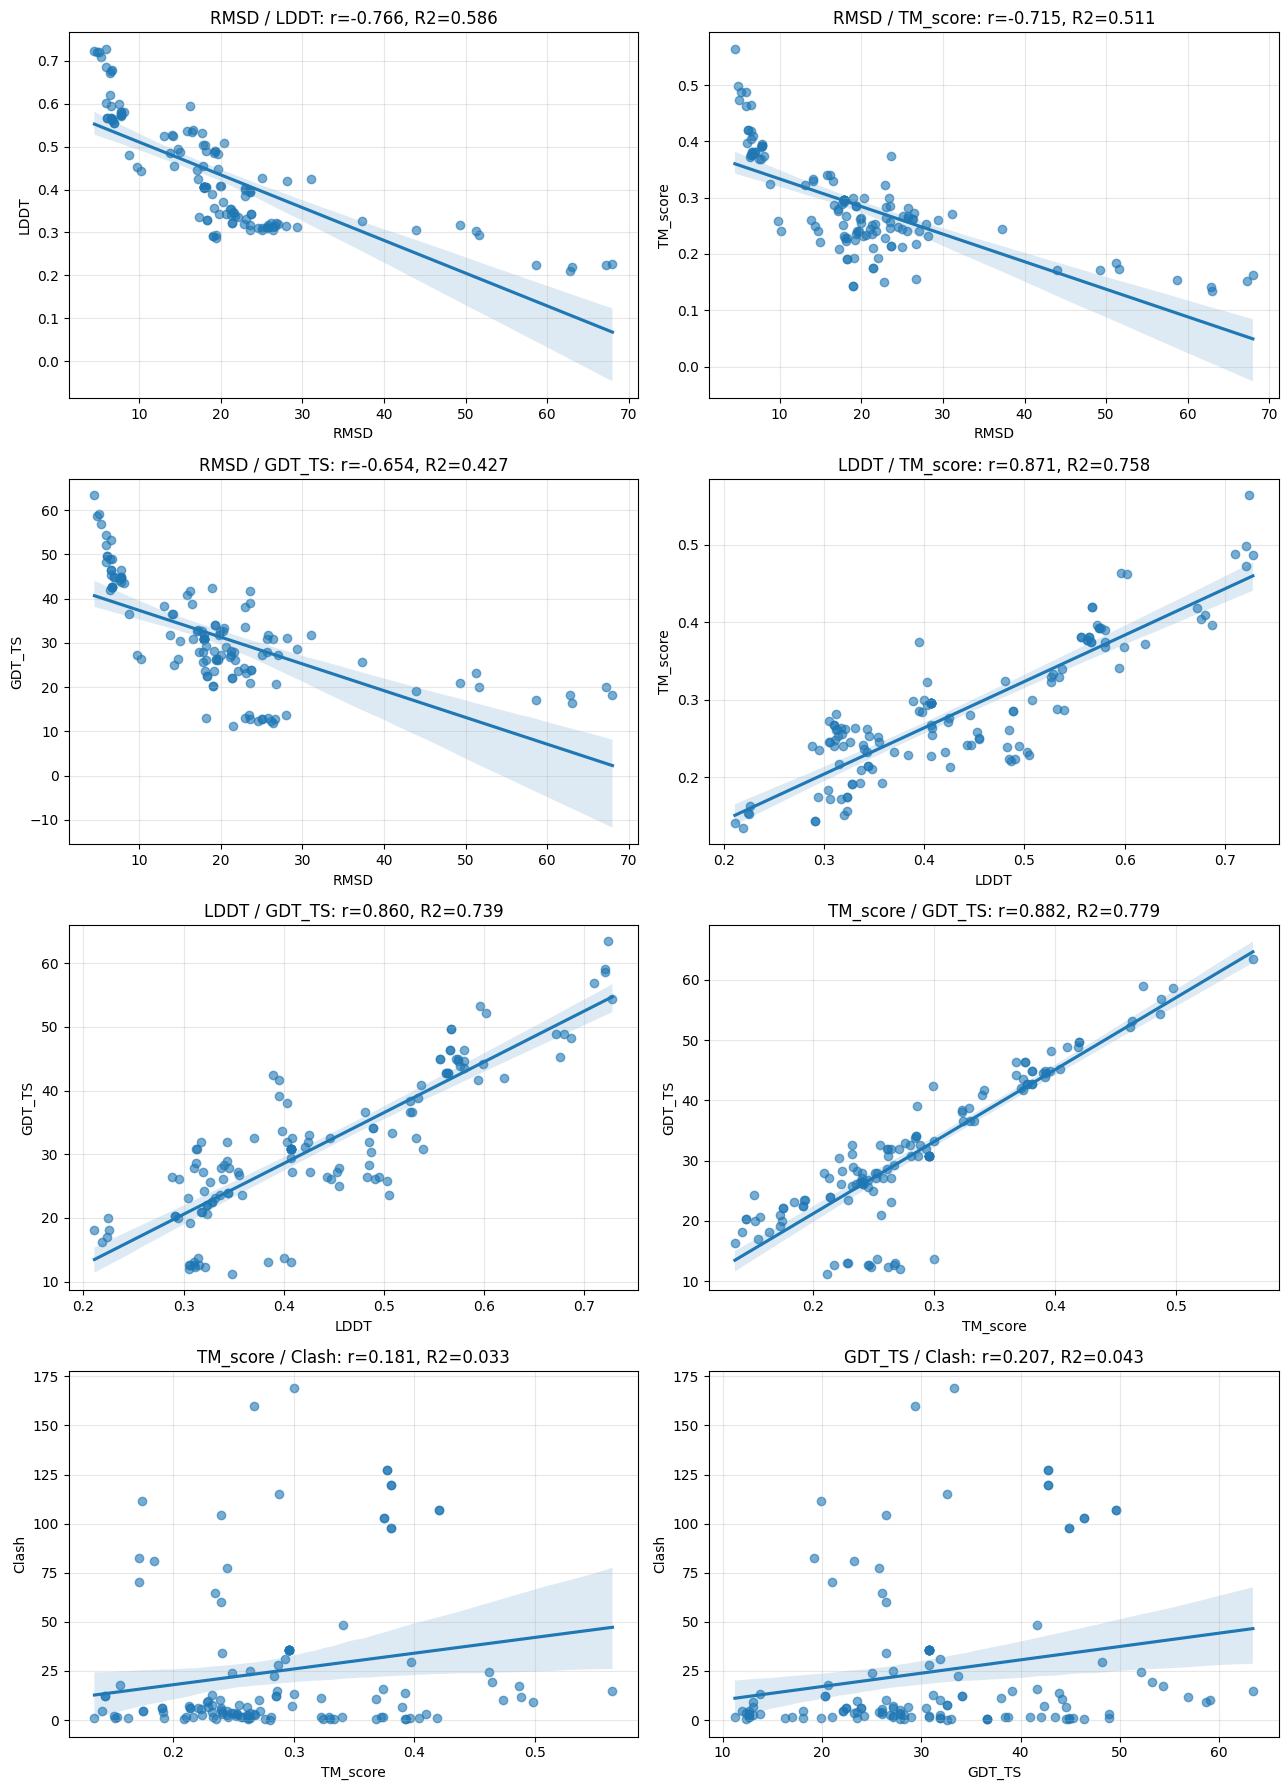

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

pary_regresji = list(
    regresja_df[["X", "Y"]].itertuples(
        index=False, name=None
    )
)

fig, axes = plt.subplots(4, 2, figsize=(13, 18))

for ax, (x, y) in zip(axes.flat, pary_regresji):
    r, p = pearsonr(df[x], df[y])

    sns.regplot(
        data=df,
        x=x,
        y=y,
        ax=ax,
        ci=95,
        scatter_kws={"alpha": 0.6}
    )

    ax.set_title(
        f"{x} / {y}: r={r:.3f}, R2={r**2:.3f}"
    )

    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


Na każdym wykresie punkty reprezentują modele RNA, prosta przedstawia dopasowaną regresję liniową, a półprzezroczysty obszar oznacza 95-procentowy przedział ufności dla średniej przewidywanej odpowiedzi.


# Analiza korelacji Pearsona i regresji liniowej



W celu dokładniejszego zbadania zależności między metrykami obliczono współczynniki korelacji Pearsona dla ośmiu par, które wykazały istotną korelację Spearmana. Przyjęto hipotezę zerową zakładającą brak korelacji liniowej oraz poziom istotności α = 0,05.

Najsilniejszą dodatnią korelację liniową stwierdzono między TM_score i GDT_TS (r = 0,882; p < 0,001). Współczynnik determinacji R² = 0,779 oznacza, że model regresji liniowej wyjaśnia około 77,9% zmienności GDT_TS.

Silne dodatnie zależności występują również między LDDT i TM_score (r = 0,871) oraz LDDT i GDT_TS (r = 0,860).

Najsilniejszą ujemną korelację zaobserwowano między RMSD i LDDT (r = -0,766; p < 0,001). Oznacza to, że modele o większym odchyleniu od struktury referencyjnej zazwyczaj wykazują mniejszą zgodność lokalną.

Dla metryki Clash korelacje liniowe z TM_score i GDT_TS okazały się bardzo słabe, mimo uzyskania nominalnej istotności statystycznej. Oznacza to, że zależności te mają niewielkie znaczenie dla wyjaśniania zmienności danych.

**Wnioski:** Analiza regresji liniowej potwierdziła występowanie silnych zależności między metrykami opisującymi podobieństwo strukturalne modeli RNA. Najlepsze dopasowanie liniowe uzyskano dla pary TM_score i GDT_TS. Metryka Clash wykazuje znacznie słabsze zależności z pozostałymi wskaźnikami.

# Analiza normalności rozkładów

# Wykresy Q-Q przed transformacją


Wykres Q-Q (quantile-quantile) porównuje kwantyle rzeczywistych danych z kwantylami teoretycznego rozkładu normalnego.
- Jeżeli punkty układają się wzdłuż prostej, rozkład jest zbliżony do normalnego.
- Jeżeli punkty wyraźnie odchodzą od prostej, występują odstępstwa od normalności.
- Zakrzywienie lub odchylenia na końcach wykresu mogą świadczyć o asymetrii i nietypowych ogonach rozkładu.

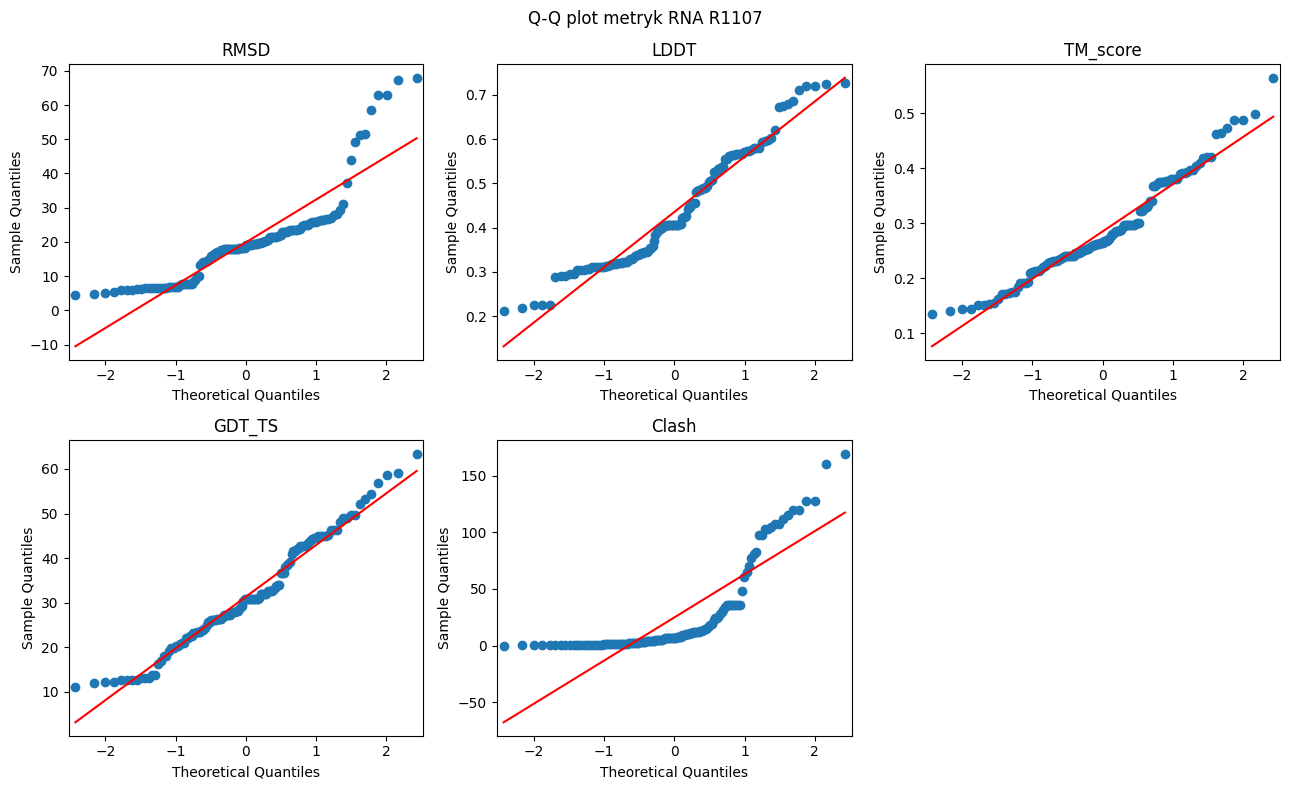

In [ ]:

import matplotlib.pyplot as plt
import statsmodels.api as sm

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for ax, metryka in zip(axes.flat, metryki):
    sm.qqplot(
        df[metryka].dropna(),
        line="s",
        ax=ax
    )

    ax.set_title(metryka)

axes.flat[-1].axis("off")

plt.suptitle("Q-Q plot metryk RNA R1107")
plt.tight_layout()
plt.show()


# Test Sharpiro-Wilka

# Test Shapiro-Wilka: hipotezy
Test Shapiro-Wilka pozwala sprawdzić, czy dane są zgodne z rozkładem normalnym.

Przyjmujemy:
- H₀: badana metryka pochodzi z populacji o rozkładzie normalnym.
- H₁: rozkład badanej metryki różni się od normalnego.
- Poziom istotności: alpha=0,05.
Interpretacja:
- Gdy p < 0,05, odrzucamy H₀. Rozkład istotnie odbiega od normalnego.
- Gdy p = 0,05 , nie mamy podstaw do odrzucenia H₀. Nie oznacza to jednak udowodnienia normalności.
Test podaje także statystykę W, która przyjmuje wartości od 0 do 1. Im bliżej 1, tym zwykle lepsza zgodność z rozkładem normalnym.

In [ ]:

from scipy.stats import shapiro
import pandas as pd

metryki = ["RMSD", "LDDT", "TM_score",
           "GDT_TS", "Clash"]

alpha = 0.05
wyniki = []

for metryka in metryki:
    W, p = shapiro(df[metryka].dropna())

    wyniki.append({
        "Metryka": metryka,
        "W": W,
        "p-value": p,
        "Normalność": (
            "Brak podstaw do odrzucenia H0"
            if p >= alpha else "Odrzucamy H0"
        )
    })

shapiro_przed = pd.DataFrame(wyniki)
display(shapiro_przed)


,Metryka,W,p-value,Normalność
0,RMSD,0.801595,5.020518e-12,Odrzucamy H0
1,LDDT,0.946729,6.000356e-05,Odrzucamy H0
2,TM_score,0.956668,3.607156e-04,Odrzucamy H0
3,GDT_TS,0.970020,5.352843e-03,Odrzucamy H0
4,Clash,0.662817,6.240495e-16,Odrzucamy H0


RMSD i Clash mają szczególnie silne odstępstwa od normalności. Jest to zgodne z wcześniejszymi histogramami, na których występowały długie prawe ogony i wartości odstające.

W wynikach największe odchylenia w górnych kwantylach pojawiają się dla RMSD i Clash. Potwierdza to silną prawostronną asymetrię tych metryk.

# Transformacja logitowa

Transformację wykonujemy tylko dla trzech metryk: LDDT, TM_score i GDT_TS.

Stosujemy wzór:

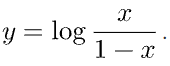

Transformacja logitowa przekształca wartości z przedziału (0, 1) na wartości z zakresu od ujemnej nieskonczoności do pozytywnej nieskonczoniści. Może zmniejszyć asymetrię i poprawić zgodność rozkładu z normalnym, ale nie gwarantuje takiego efektu.

Ważne: wartości GDT_TS są podawane w skali 0–100, dlatego najpierw dzielimy je przez 100.

In [ ]:

import numpy as np
from scipy.special import logit

epsilon = 1e-6

df["LDDT_logit"] = logit(
    df["LDDT"].clip(epsilon, 1 - epsilon)
)

df["TM_score_logit"] = logit(
    df["TM_score"].clip(epsilon, 1 - epsilon)
)

df["GDT_TS_logit"] = logit(
    (df["GDT_TS"] / 100).clip(
        epsilon, 1 - epsilon
    )
)

display(df[
    ["LDDT_logit", "TM_score_logit",
     "GDT_TS_logit"]
].head())


,LDDT_logit,TM_score_logit,GDT_TS_logit
0,0.964391,0.257412,0.549847
1,0.949427,-0.008000,0.351165
2,0.895384,-0.048009,0.276957
3,0.984499,-0.052012,0.174038
4,0.949427,-0.108105,0.366446


Wyniki testu Shapiro-Wilka po transformacji:
LDDT: W wzrosło z 0,9467 do 0,9569, ale p nadal jest mniejsze od 0,05. Rozkład nadal istotnie odbiega od normalnego.



TM_score: W wzrosło z 0,9567 do 0,9812, a p wzrosło do 0,0659. Nie mamy podstaw do odrzucenia hipotezy o normalności.



GDT_TS: W wzrosło z 0,9700 do 0,9791, jednak p = 0,0408. Nadal odrzucamy hipotezę zerową, choć odstępstwa od normalności są mniejsze.

# Kod testu po transformacji

In [ ]:

metryki_logit = [
    "LDDT_logit",
    "TM_score_logit",
    "GDT_TS_logit"
]

wyniki_po = []

for metryka in metryki_logit:
    W, p = shapiro(df[metryka].dropna())

    wyniki_po.append({
        "Metryka": metryka,
        "W": W,
        "p-value": p,
        "Normalność": (
            "Brak podstaw do odrzucenia H0"
            if p >= 0.05 else "Odrzucamy H0"
        )
    })

shapiro_po = pd.DataFrame(wyniki_po)
display(shapiro_po)


,Metryka,W,p-value,Normalność
0,LDDT_logit,0.956901,0.000377,Odrzucamy H0
1,TM_score_logit,0.981156,0.065913,Brak podstaw do odrzucenia H0
2,GDT_TS_logit,0.979092,0.040848,Odrzucamy H0


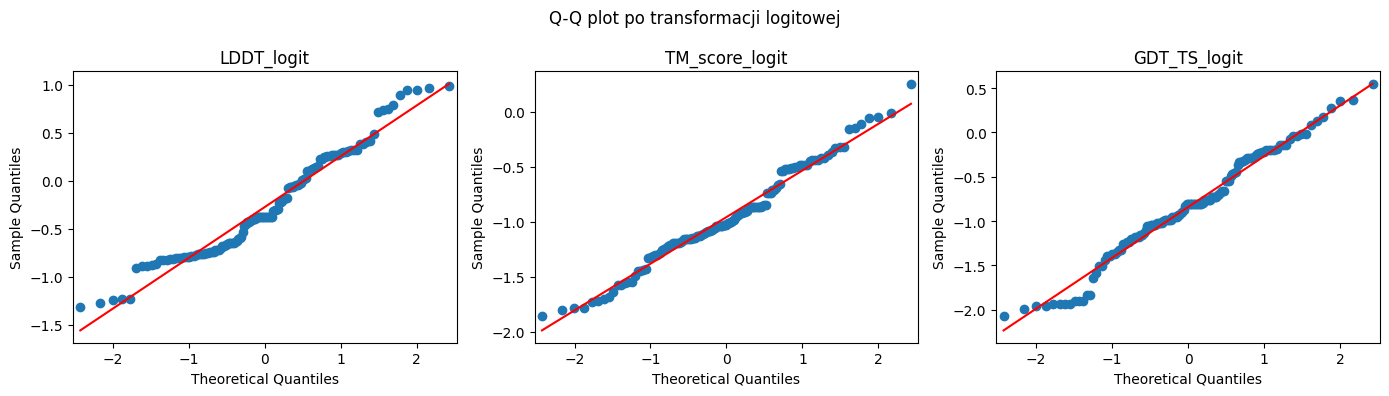

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metryka in zip(axes, metryki_logit):
    sm.qqplot(
        df[metryka].dropna(),
        line="s",
        ax=ax
    )

    ax.set_title(metryka)

plt.suptitle("Q-Q plot po transformacji logitowej")
plt.tight_layout()
plt.show()


W porównaniu z wykresami oryginalnymi punkty wykazują ogólnie lepsze dopasowanie do linii teoretycznej, szczególnie dla TM_score.

# Podsumowanie



Normalność rozkładów pięciu metryk oceny modeli RNA sprawdzono za pomocą wykresów Q-Q oraz testu Shapiro-Wilka. Przyjęto hipotezę zerową zakładającą normalność rozkładu i poziom istotności α = 0,05.

Przed transformacją wszystkie metryki wykazały istotne statystycznie odstępstwa od rozkładu normalnego (p < 0,05). Największe odstępstwa wystąpiły dla RMSD (W = 0,8016) oraz Clash (W = 0,6628), co potwierdzają również ich wykresy Q-Q.

Następnie dla metryk LDDT, TM_score i GDT_TS zastosowano transformację logitową, przy czym wartości GDT_TS wcześniej podzielono przez 100.

Po transformacji wszystkie trzy metryki uzyskały wyższe wartości statystyki W, co wskazuje na poprawę zgodności rozkładów z normalnym.

Największą poprawę uzyskano dla TM_score, gdzie wartość p wzrosła z 0,000361 do 0,065913. Oznacza to, że po transformacji nie ma podstaw do odrzucenia hipotezy o normalności rozkładu.

Dla LDDT (p = 0,000377) oraz GDT_TS (p = 0,040848) nadal stwierdzono istotne odstępstwa od normalności, pomimo poprawy statystyki W.

**Wniosek:** Transformacja logitowa poprawiła zgodność rozkładów trzech analizowanych metryk z rozkładem normalnym, jednak tylko w przypadku TM_score wynik testu Shapiro-Wilka przestał być istotny statystycznie przy α = 0,05. Transformacja nie gwarantuje więc osiągnięcia normalności dla wszystkich metryk.